# Assignment 2
## Chapter 4 exercise 1, 2, 3, 13, 14
## Chapter 5 exercise 1, 2, 5, 6


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from IPython.display import display
from ISLP import load_data, confusion_table
from ISLP.models import ModelSpec as MS, summarize
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA, QuadraticDiscriminantAnalysis as QDA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

## Chapter 4, Exercise 13

### (a) Numerical and graphical summaries of `Weekly`

In [13]:
Weekly = load_data("Weekly")
returns = Weekly["Today"]

# Numerical summaries
display(Weekly.describe(include="all"))
display(Weekly.drop(columns="Direction").corr())

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Direction
count,1089.000000,1089.000000,1089.000000,1089.000000,1089.000000,1089.000000,1089.000000,1089.000000,1089
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Up
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,605
mean,2000.048669,0.150585,0.151079,0.147205,0.145818,0.139893,1.574618,0.149899,NaN
std,6.033182,2.357013,2.357254,2.360502,2.360279,2.361285,1.686636,2.356927,NaN
min,1990.000000,-18.195000,-18.195000,-18.195000,-18.195000,-18.195000,0.087465,-18.195000,NaN
25%,1995.000000,-1.154000,-1.154000,-1.158000,-1.158000,-1.166000,0.332022,-1.154000,NaN
50%,2000.000000,0.241000,0.241000,0.241000,0.238000,0.234000,1.002680,0.241000,NaN
75%,2005.000000,1.405000,1.409000,1.409000,1.409000,1.405000,2.053727,1.405000,NaN


,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today
Year,1.000000,-0.032289,-0.033390,-0.030006,-0.031128,-0.030519,0.841942,-0.032460
Lag1,-0.032289,1.000000,-0.074853,0.058636,-0.071274,-0.008183,-0.064951,-0.075032
Lag2,-0.033390,-0.074853,1.000000,-0.075721,0.058382,-0.072499,-0.085513,0.059167
Lag3,-0.030006,0.058636,-0.075721,1.000000,-0.075396,0.060657,-0.069288,-0.071244
Lag4,-0.031128,-0.071274,0.058382,-0.075396,1.000000,-0.075675,-0.061075,-0.007826
Lag5,-0.030519,-0.008183,-0.072499,0.060657,-0.075675,1.000000,-0.058517,0.011013
Volume,0.841942,-0.064951,-0.085513,-0.069288,-0.061075,-0.058517,1.000000,-0.033078
Today,-0.032460,-0.075032,0.059167,-0.071244,-0.007826,0.011013,-0.033078,1.000000


In [14]:
display(pd.Series({
    "mean": returns.mean(),
    "sd": returns.std(),
    "skewness": stats.skew(returns),
    "excess kurtosis": stats.kurtosis(returns),
    "share Up": (Weekly["Direction"] == "Up").mean(),
}).round(3).to_frame("Today"))

# Time axis in fractional years (the data has no dates, only Year)
t = Weekly["Year"] + Weekly.groupby("Year").cumcount() / Weekly.groupby("Year")["Year"].transform("size")

,Today
mean,0.150
sd,2.357
skewness,-0.481
excess kurtosis,5.685
share Up,0.556


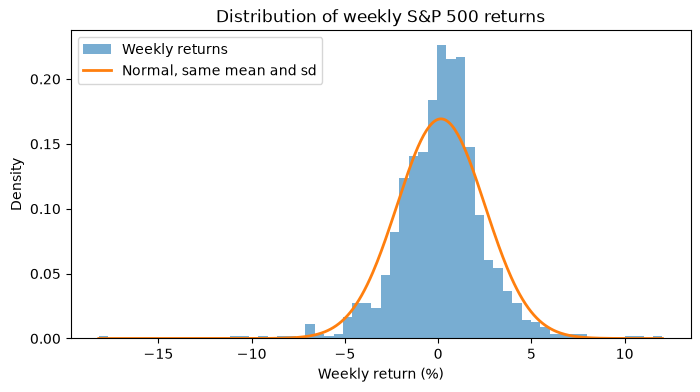

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(returns, bins=60, density=True, alpha=0.6, label="Weekly returns")
x = np.linspace(returns.min(), returns.max(), 400)
ax.plot(x, stats.norm.pdf(x, returns.mean(), returns.std()), lw=2, label="Normal, same mean and sd")
ax.set(xlabel="Weekly return (%)", ylabel="Density", title="Distribution of weekly S&P 500 returns")
ax.legend()
plt.show()

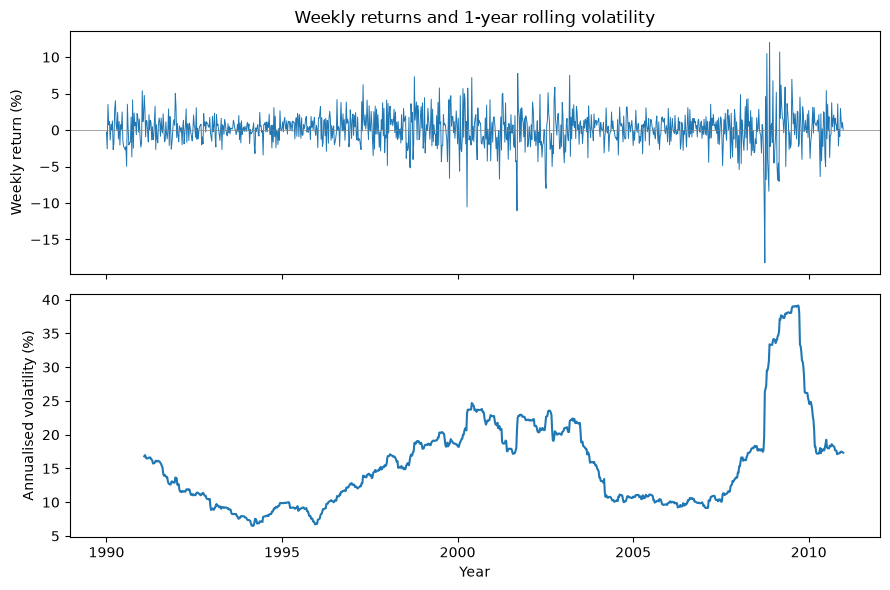

In [16]:
vol_52w = returns.rolling(52).std() * np.sqrt(52)  # 52 weeks = 1 year, annualised

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(t, returns, lw=0.7)
axes[0].axhline(0, color="grey", lw=0.5)
axes[0].set(ylabel="Weekly return (%)", title="Weekly returns and 1-year rolling volatility")
axes[1].plot(t, vol_52w)
axes[1].set(xlabel="Year", ylabel="Annualised volatility (%)")
fig.tight_layout()
plt.show()

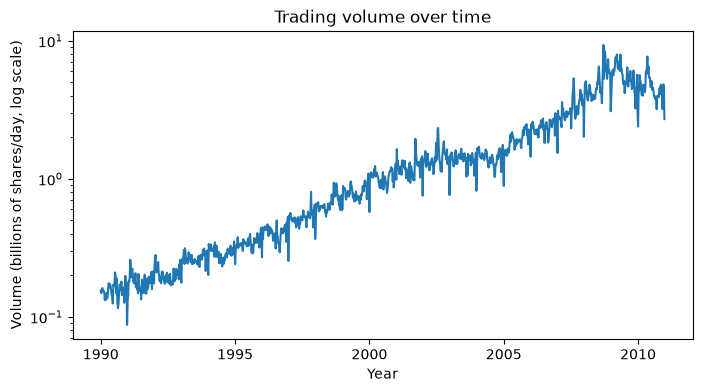

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t, Weekly["Volume"])
ax.set_yscale("log")
ax.set(xlabel="Year", ylabel="Volume (billions of shares/day, log scale)", title="Trading volume over time")
plt.show()

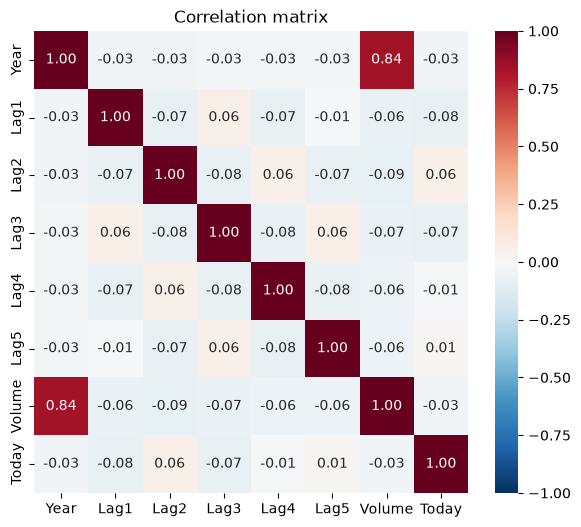

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(Weekly.drop(columns="Direction").corr(), annot=True, fmt=".2f",
            cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation matrix")
plt.show()

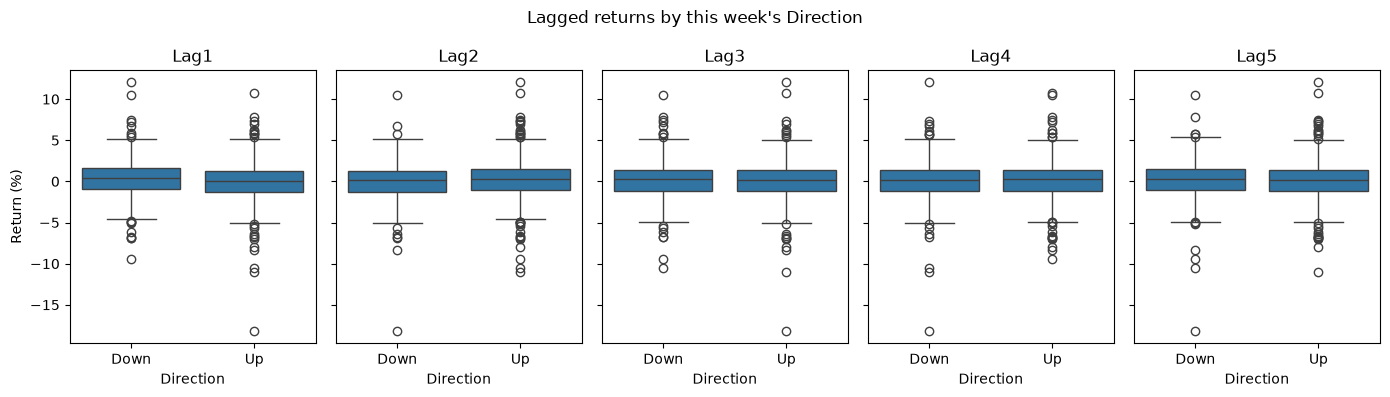

,Lag1,Lag2,Lag3,Lag4,Lag5
Direction,,,,,
Down,0.282,-0.040,0.208,0.200,0.188
Up,0.045,0.304,0.099,0.102,0.102


In [19]:
fig, axes = plt.subplots(1, 5, figsize=(14, 4), sharey=True)
for ax, lag in zip(axes, ["Lag1", "Lag2", "Lag3", "Lag4", "Lag5"]):
    sns.boxplot(data=Weekly, x="Direction", y=lag, ax=ax)
    ax.set(title=lag, ylabel="Return (%)")
fig.suptitle("Lagged returns by this week's Direction")
fig.tight_layout()
plt.show()

display(Weekly.groupby("Direction", observed=True)[["Lag1", "Lag2", "Lag3", "Lag4", "Lag5"]].mean().round(3))

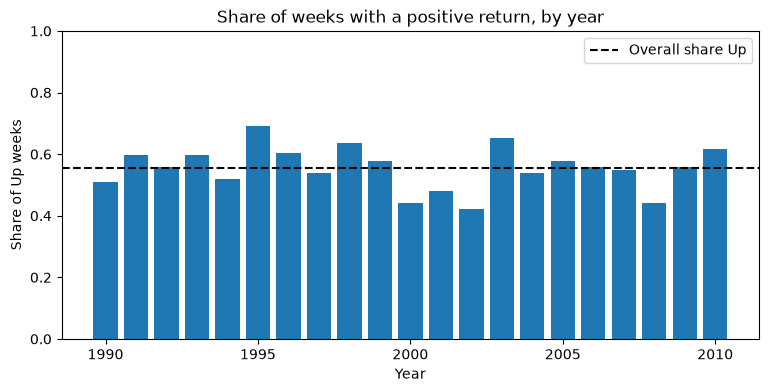

In [20]:
up_share = Weekly.groupby("Year")["Direction"].apply(lambda d: (d == "Up").mean())

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(up_share.index, up_share.values)
ax.axhline((Weekly["Direction"] == "Up").mean(), color="black", ls="--", label="Overall share Up")
ax.set(xlabel="Year", ylabel="Share of Up weeks", ylim=(0, 1),
       title="Share of weeks with a positive return, by year")
ax.legend()
plt.show()

**Interpretation.** The data contain 1,089 weekly S&P 500 returns from 1990 to 2010.

**Distribution of returns.** The mean weekly return is 0.15 % with a standard deviation of 2.36 %, so the average week is close to zero relative to its spread. The distribution is not normal: it is more peaked around zero and has much heavier tails than a normal distribution with the same mean and variance (excess kurtosis 5.7, skewness −0.48). There are 13 weeks with a return beyond ±3 standard deviations, compared with about 3 expected under normality, and both the largest loss (−18.2 %) and the largest gain (+12.0 %) occur in 2008. The negative skew means large drops are more extreme than large gains.

**Volatility.** Volatility is clearly not constant. The 1-year rolling volatility (annualised) ranges from 6.5 % in early 1994 to 39.1 % in late 2009, compared with 17.0 % over the full sample. Calm and turbulent periods cluster: volatility rises through the late 1990s, stays high during the 2000–2002 dot-com crash, falls back to around 10 % in 2004–2007 and spikes during the 2008 financial crisis. Large moves tend to be followed by large moves, even though their sign is unpredictable.

**Volume.** The only strong pattern in the data is the trend in Volume, which has a correlation of 0.84 with Year and rises from about 0.15 to 4.6 billion shares per day. On a log scale the increase is roughly linear, so volume has grown approximately exponentially.

**Predictability of returns.** The lag variables are almost uncorrelated with Today (all correlations between −0.075 and 0.059), and Volume is essentially uncorrelated with Today (−0.033). The boxplots show that the distributions of the lagged returns overlap almost completely for "Up" and "Down" weeks. The largest difference is in Lag2, with a mean of 0.30 % in "Up" weeks versus −0.04 % in "Down" weeks, which is small compared with the standard deviation of 2.36 %. Overall, 55.6 % of weeks are "Up", and the share varies between 42 % and 69 % across years.

**Conclusion.** Apart from the upward trend in Volume and the time-varying volatility, there is little evidence of a pattern that would help predict the direction of the market. Past returns carry at most weak information about this week's return, so we should not expect a classifier to do much better than the 55.6 % accuracy obtained by always predicting "Up".

### (b) Logistic regression on the full data set

In [21]:
predictors = ["Lag1", "Lag2", "Lag3", "Lag4", "Lag5", "Volume"]
X = MS(predictors).fit_transform(Weekly)   # adds intercept
y = Weekly["Direction"] == "Up"            # True/False → 1/0

glm = sm.GLM(y, X, family=sm.families.Binomial())
results = glm.fit()
summarize(results)

,coef,std err,z,P>|z|
intercept,0.2669,0.086,3.106,0.002
Lag1,-0.0413,0.026,-1.563,0.118
Lag2,0.0584,0.027,2.175,0.030
Lag3,-0.0161,0.027,-0.602,0.547
Lag4,-0.0278,0.026,-1.050,0.294
Lag5,-0.0145,0.026,-0.549,0.583
Volume,-0.0227,0.037,-0.616,0.538


Looking at the p-values for the coefficient estimates, we see that only Lag2 is significant at the 5% significance level.

### (c) Confusion matrix and overall fraction of correct predictions

In [22]:
probs = results.predict()
threshold = 0.5
labels = np.where(probs > threshold, "Up", "Down")
display(confusion_table(labels, Weekly["Direction"]))
display(pd.Series(probs).describe().round(3).to_frame("P(Up)"))
print(f"The accuracy of the logistic classification with threshold = {threshold} is {np.mean(labels == Weekly['Direction']):.2%}")

Truth,Down,Up
Predicted,,
Down,54,48
Up,430,557


,P(Up)
count,1089.000
mean,0.556
std,0.047
min,0.286
25%,0.528
50%,0.557
75%,0.582
max,0.784


The accuracy of the logistic classification with threshold = 0.5 is 56.11%


The confusion matrix is for the logistic regression from (b), with all six predictors and a threshold of 0.5, evaluated on the full data set. It shows the two types of mistakes a classifier can make: false positives and false negatives. If we define "Up" as the positive class, a false positive is a week where the model predicts "Up" but the actual class is "Down", and a false negative is a week where the model predicts "Down" but the actual class is "Up".

The model is correct in $(557 + 54)/1089 \approx 56.1\%$ of the weeks. This is barely better than the trivial rule of always predicting "Up", which is correct in $605/1089 \approx 55.6\%$ of the weeks. The two types of mistakes are also very unevenly distributed:

$$\text{TPR} = \frac{TP}{P} = \frac{557}{605} \approx 0.921, \qquad \text{TNR} = \frac{TN}{N} = \frac{54}{484} \approx 0.112$$

The model finds 92.1 % of the "Up" weeks but only 11.2 % of the "Down" weeks. Of the 478 misclassified weeks, 430 are false positives and only 48 are false negatives. In other words, the model labels almost every "Down" week as "Up", and it predicts "Up" in 987 of the 1089 weeks.

The reason is the structure of the data. As seen in (a) and (b), the predictors have very weak predictive power: their correlations with Today are close to zero, and only Lag2 is significant. At the same time, "Up" is slightly more common than "Down" (55.6 % versus 44.4 %). With weak predictors, the fitted probability $\hat P(\text{Up} \mid X)$ stays close to this base rate for almost every week. Its median is 0.557, and half of the weeks lie between 0.528 and 0.582. With a threshold of 0.5, nearly all predictions therefore become "Up". The model mostly reproduces the majority class instead of separating the two classes.

### (d) Logistic regression with Lag2, trained on 1990–2008 and tested on 2009–2010

In [23]:
# using only Lag2 as the regressor
predictors = ["Lag2"]
Weekly_train = Weekly[Weekly["Year"] < 2009]
Weekly_test = Weekly[Weekly["Year"] >= 2009]

design = MS(predictors).fit(Weekly_train)   # fit the design on training data only
X_train = design.transform(Weekly_train)    # adds intercept
X_test = design.transform(Weekly_test)      # same columns, also with intercept
y_train = Weekly_train["Direction"] == "Up"

glm = sm.GLM(y_train, X_train, family=sm.families.Binomial())
results = glm.fit()
display(summarize(results))

probs = results.predict(X_test)             # predict on the held-out 2009–2010 data
threshold = 0.5
labels = np.where(probs > threshold, "Up", "Down")
preds = {"(d) Logistic": labels}         # stored for the comparison in (i)
display(confusion_table(labels, Weekly_test["Direction"]))

accuracy = np.mean(labels == Weekly_test["Direction"])
print(f"Test accuracy with threshold = {threshold}: {accuracy:.2%}")

,coef,std err,z,P>|z|
intercept,0.2033,0.064,3.162,0.002
Lag2,0.0581,0.029,2.024,0.043


Truth,Down,Up
Predicted,,
Down,9,5
Up,34,56


Test accuracy with threshold = 0.5: 62.50%


### (e)–(h) LDA, QDA, KNN with K = 1 and naive Bayes

In [24]:
X_train_sk = Weekly_train[["Lag2"]]   # without intercept
X_test_sk = Weekly_test[["Lag2"]]

models = {
    "(e) LDA": LDA(),
    "(f) QDA": QDA(),
    "(g) KNN, K = 1": KNeighborsClassifier(n_neighbors=1),
    "(h) Naive Bayes": GaussianNB(),
}

accuracy = {}
for name, model in models.items():
    model.fit(X_train_sk, Weekly_train["Direction"])
    labels = model.predict(X_test_sk)
    preds[name] = labels
    accuracy[name] = np.mean(labels == Weekly_test["Direction"])
    print(f"{name}: test accuracy {accuracy[name]:.2%}")
    display(confusion_table(labels, Weekly_test["Direction"]))

(e) LDA: test accuracy 62.50%


Truth,Down,Up
Predicted,,
Down,9,5
Up,34,56


(f) QDA: test accuracy 58.65%


Truth,Down,Up
Predicted,,
Down,0,0
Up,43,61


(g) KNN, K = 1: test accuracy 50.00%


Truth,Down,Up
Predicted,,
Down,21,30
Up,22,31


(h) Naive Bayes: test accuracy 58.65%


Truth,Down,Up
Predicted,,
Down,0,0
Up,43,61


### (i) Which method gives the best results?

In [25]:
truth = Weekly_test["Direction"].to_numpy()
preds["Baseline: always Up"] = np.full(len(truth), "Up")

def metrics(pred):
    tp = np.sum((pred == "Up") & (truth == "Up"))
    tn = np.sum((pred == "Down") & (truth == "Down"))
    fp = np.sum((pred == "Up") & (truth == "Down"))
    fn = np.sum((pred == "Down") & (truth == "Up"))
    return {
        "accuracy": (tp + tn) / len(truth),
        "recall Up": tp / (tp + fn),
        "recall Down": tn / (tn + fp),
        "precision Up": tp / (tp + fp) if tp + fp > 0 else np.nan,
        "precision Down": tn / (tn + fn) if tn + fn > 0 else np.nan,
        "# predicted Down": tn + fn,
    }

comparison = pd.DataFrame({name: metrics(p) for name, p in preds.items()}).T
display(comparison.round(3).sort_values("accuracy", ascending=False).style.format(precision=3))

# Where do logistic regression and LDA put the boundary?  P(Up) = 0.5  <=>  b0 + b1 * Lag2 = 0
lda = LDA().fit(X_train_sk, Weekly_train["Direction"])
print(f"Logistic cut-off: Lag2 = {-results.params['intercept'] / results.params['Lag2']:.2f}")
print(f"LDA cut-off:      Lag2 = {-lda.intercept_[0] / lda.coef_[0, 0]:.2f}")

# Is 65/104 correct better than the 61/104 of always predicting Up?
n_correct = int(round(comparison.loc["(d) Logistic", "accuracy"] * len(truth)))
p_value = stats.binomtest(n_correct, len(truth), comparison.loc["Baseline: always Up", "accuracy"],
                          alternative="greater").pvalue
print(f"One-sided binomial test vs. always Up: p = {p_value:.2f}")

,accuracy,recall Up,recall Down,precision Up,precision Down,# predicted Down
(d) Logistic,0.625,0.918,0.209,0.622,0.643,14.000
(e) LDA,0.625,0.918,0.209,0.622,0.643,14.000
(f) QDA,0.587,1.000,0.000,0.587,nan,0.000
(h) Naive Bayes,0.587,1.000,0.000,0.587,nan,0.000
Baseline: always Up,0.587,1.000,0.000,0.587,nan,0.000
"(g) KNN, K = 1",0.500,0.508,0.488,0.585,0.412,51.000


Logistic cut-off: Lag2 = -3.50
LDA cut-off:      Lag2 = -3.52
One-sided binomial test vs. always Up: p = 0.24


**Metrics.** "Up" is treated as the positive class. Recall "Up" is the share of actual "Up" weeks that were predicted "Up", and recall "Down" is the same for "Down" weeks. Precision is the share of predictions of a class that were correct. Precision "Down" is undefined (NaN) for models that never predict "Down".

**Two features of the data explain all the confusion matrices.** First, the signal in Lag2 is very weak. In part (a), Lag2 had a correlation of only 0.06 with Today, and its mean differs by about 0.3 percentage points between "Up" and "Down" weeks, against a standard deviation of about 2.3. The two class-conditional distributions of Lag2 therefore overlap almost completely, so every model's estimate of P("Up" | Lag2) stays close to the prior. Second, the classes are imbalanced: 55.2 % of training weeks and 58.7 % of test weeks are "Up". When the posterior is close to the prior and the prior favours "Up", a model with a 0.5 threshold will predict "Up" almost everywhere.

**Logistic regression and LDA (62.5 %).** With a single predictor, both methods produce a decision rule that is linear in Lag2, so it reduces to one cut-off. The cut-offs are almost identical: "Down" is predicted only when Lag2 < −3.50 (logistic) or −3.52 (LDA). As a result, the two methods give exactly the same predictions on the test set. They predict "Down" only after a large fall two weeks earlier. That happened in 14 of the 104 test weeks, more often than usual because 2009 followed the financial crisis and was unusually volatile. In 9 of those 14 weeks the market did fall (precision "Down" 64 %). The models therefore catch only 9 of the 43 "Down" weeks (recall "Down" 21 %) while catching 56 of the 61 "Up" weeks (recall "Up" 92 %). Most errors are "Down" weeks predicted as "Up".

**QDA and naive Bayes (58.7 %).** With one predictor, the naive Bayes independence assumption is irrelevant, so Gaussian naive Bayes is the same model as QDA and the two confusion matrices are identical. The estimated variance of Lag2 is larger for "Up" weeks than for "Down" weeks, so "Up" wins in both tails. In the middle, the class means are so close that "Down" never overcomes the larger prior of "Up". The estimated P("Up") is above 0.5 for every value of Lag2, so both models predict "Up" for every week (recall "Up" 100 %, recall "Down" 0 %). Their accuracy equals the share of "Up" weeks in the test period: they do no better than the trivial baseline.

**KNN with K = 1 (50.0 %).** KNN with K = 1 is the most flexible method and has the highest variance: each prediction copies the label of the single nearest training week. Because the classes overlap almost completely in Lag2, that label is close to a coin flip. KNN is the only method that predicts "Down" often (51 times), and its recalls for both classes are about 50 %. It ignores the class imbalance and fits noise, so it ends up below the baseline.

**Conclusion.** Logistic regression and LDA give the best results (62.5 % accuracy, the highest precision for both classes and the only non-trivial recall for "Down"). However, the improvement over always predicting "Up" is only 4 weeks out of 104. A one-sided binomial test against the baseline accuracy of 58.7 % gives p = 0.24, so the difference could easily be due to chance. This agrees with part (a): past returns carry little information about the direction of the market, and the simple linear methods win mainly because they do not try to fit structure that is not there.

### Testing different model specifications

In [26]:
Weekly["Lag2_sq"] = Weekly["Lag2"] ** 2
Weekly["Lag1_x_Lag2"] = Weekly["Lag1"] * Weekly["Lag2"]
Weekly["log_Volume"] = np.log(Weekly["Volume"])

Weekly_train = Weekly[Weekly["Year"] < 2009]
Weekly_test = Weekly[Weekly["Year"] >= 2009]

feature_sets = {
    "Lag2": ["Lag2"],                                         # reference from (d)–(h)
    "Lag1 + Lag2": ["Lag1", "Lag2"],                          # the two strongest in (b)
    "Lag1–Lag5": ["Lag1", "Lag2", "Lag3", "Lag4", "Lag5"],    # all lags
    "Lag2 + log Volume": ["Lag2", "log_Volume"],              # adds volume
    "Lag2 + Lag2²": ["Lag2", "Lag2_sq"],                      # transformation
    "Lag1 + Lag2 + Lag1·Lag2": ["Lag1", "Lag2", "Lag1_x_Lag2"],  # interaction
}

results_j = []
methods = {
    "Logistic": lambda: LogisticRegression(C=np.inf),   # no regularisation, same as statsmodels
    "LDA": LDA,
    "QDA": QDA,
    "Naive Bayes": GaussianNB,
}
for K in [1, 5, 10, 20, 50, 100]:
    methods[f"KNN, K = {K}"] = lambda K=K: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=K))
for set_name, cols in feature_sets.items():
    for method_name, make_model in methods.items():
        model = make_model()
        model.fit(Weekly_train[cols], Weekly_train["Direction"])
        pred = model.predict(Weekly_test[cols])
        results_j.append({"features": set_name, "method": method_name, **metrics(pred)})

results_j = pd.DataFrame(results_j)
results_j["balanced accuracy"] = (results_j["recall Up"] + results_j["recall Down"]) / 2

def show_best(metric):
    """Rank all combinations by `metric` and show the confusion matrix of the best one."""
    tie_breaker = "balanced accuracy" if metric == "accuracy" else "accuracy"
    ranked = results_j.sort_values([metric, tie_breaker], ascending=False)
    display(ranked.round(3).head(10))

    best = ranked.iloc[0]
    cols = feature_sets[best["features"]]
    best_model = methods[best["method"]]()
    best_model.fit(Weekly_train[cols], Weekly_train["Direction"])
    print(f"Best by {metric}: {best['method']} with {best['features']}")
    display(confusion_table(best_model.predict(Weekly_test[cols]), Weekly_test["Direction"]))

show_best("accuracy")
show_best("balanced accuracy")

,features,method,accuracy,recall Up,recall Down,precision Up,precision Down,# predicted Down,balanced accuracy
0,Lag2,Logistic,0.625,0.918,0.209,0.622,0.643,14,0.564
1,Lag2,LDA,0.625,0.918,0.209,0.622,0.643,14,0.564
40,Lag2 + Lag2²,Logistic,0.625,0.934,0.186,0.620,0.667,12,0.560
42,Lag2 + Lag2²,QDA,0.625,0.951,0.163,0.617,0.700,10,0.557
41,Lag2 + Lag2²,LDA,0.615,0.934,0.163,0.613,0.636,11,0.549
7,Lag2,"KNN, K = 20",0.596,0.639,0.535,0.661,0.511,45,0.587
47,Lag2 + Lag2²,"KNN, K = 20",0.596,0.639,0.535,0.661,0.511,45,0.587
39,Lag2 + log Volume,"KNN, K = 100",0.587,0.820,0.256,0.610,0.500,22,0.538
2,Lag2,QDA,0.587,1.000,0.000,0.587,NaN,0,0.500
3,Lag2,Naive Bayes,0.587,1.000,0.000,0.587,NaN,0,0.500


Best by accuracy: Logistic with Lag2


Truth,Down,Up
Predicted,,
Down,9,5
Up,34,56


,features,method,accuracy,recall Up,recall Down,precision Up,precision Down,# predicted Down,balanced accuracy
7,Lag2,"KNN, K = 20",0.596,0.639,0.535,0.661,0.511,45,0.587
47,Lag2 + Lag2²,"KNN, K = 20",0.596,0.639,0.535,0.661,0.511,45,0.587
34,Lag2 + log Volume,"KNN, K = 1",0.567,0.525,0.628,0.667,0.482,56,0.576
48,Lag2 + Lag2²,"KNN, K = 50",0.577,0.607,0.535,0.649,0.489,47,0.571
26,Lag1–Lag5,"KNN, K = 10",0.567,0.557,0.581,0.654,0.481,52,0.569
0,Lag2,Logistic,0.625,0.918,0.209,0.622,0.643,14,0.564
1,Lag2,LDA,0.625,0.918,0.209,0.622,0.643,14,0.564
40,Lag2 + Lag2²,Logistic,0.625,0.934,0.186,0.620,0.667,12,0.560
6,Lag2,"KNN, K = 10",0.567,0.607,0.512,0.638,0.478,46,0.559
8,Lag2,"KNN, K = 50",0.567,0.607,0.512,0.638,0.478,46,0.559


Best by balanced accuracy: KNN, K = 20 with Lag2


Truth,Down,Up
Predicted,,
Down,23,22
Up,20,39


**Interpretation.** We tried six sets of predictors with five methods (Logistic regression, LDA, QDA, naive Bayes and KNN), using $K \in \{1, 5, 10, 20, 50, 100\}$ for KNN. That gives 60 combinations, all trained on 1990–2008 and evaluated on the held-out weeks of 2009–2010.

**Best result.** The highest test accuracy is 62.5 %. Four combinations reach it: logistic regression and LDA with Lag2 alone, and logistic regression and QDA with Lag2 and Lag2². We report **logistic regression with Lag2** as the best model because it is the simplest of them. Its confusion matrix is

| | Truth: Down | Truth: Up |
|---|---|---|
| **Predicted: Down** | 9 | 5 |
| **Predicted: Up** | 34 | 56 |

This is the same model as in (d), so none of the transformations, interactions or additional predictors improved on it. The model predicts Down only 14 times. It finds 92 % of the Up weeks but only 21 % of the Down weeks, so its high accuracy comes mainly from predicting the majority class.

**Adding predictors does not help.** For the linear methods, adding Lag1, the interaction Lag1·Lag2, log Volume or all five lags lowers the test accuracy from 62.5 % to between 54.8 % and 57.7 %. These variables have almost no relationship with Direction (see (a) and (b)), so they mainly add estimation noise. The flexible methods suffer most. QDA and naive Bayes with the interaction term or with all five lags fall to 46–48 %, well below the 58.7 % obtained by always predicting Up. Only 10 of the 60 combinations beat that baseline, and 50 do worse.

**KNN.** Test accuracy for KNN varies irregularly with $K$, between 43 % and 60 %, with no clear trend. This is what we would expect when the classes overlap almost completely: small changes in $K$ or in the predictors change which neighbours are used, and the result is mostly noise. Larger $K$ makes KNN predict Up more often (with $K = 100$ it predicts Down only 22–38 times), so it moves towards the majority-class rule. The best KNN model is $K = 20$ with Lag2, at 59.6 %.

**Choice of metric.** Accuracy rewards models that lean on the majority class. If we instead rank by balanced accuracy, the average of recall Up and recall Down, the best model is KNN with $K = 20$ and Lag2 (balanced accuracy 0.587, versus 0.564 for logistic regression). It finds 23 of the 43 Down weeks (53 %) instead of 9, at the cost of more misclassified Up weeks. If the goal is to avoid losses, for example by not investing before a fall, this model may be more useful even though its overall accuracy is lower.

**Caveat.** The best model was chosen among 60 combinations based on only 104 test weeks, so its accuracy is likely somewhat optimistic. The winning margin over always predicting Up is 4 weeks, which is not statistically significant (one-sided binomial test, $p = 0.24$). The overall conclusion is the same as in (a) and (i): past returns and volume contain very little information about next week's direction, and the simplest model with the single most informative predictor performs as well as anything more complex.